<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/jobsheet%20dataset%20AntiBurnOut/JS04/04_Clustering_KMeans_DBSCAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS04: Clustering K-Means & DBSCAN - Dataset AntiBurnOut

**Identitas Mahasiswa:**
- **Nama**  : MUHAMMAD ANKA REZA
- **NIM**   : 254107023002
- **Kelas** : TI/3H

---

### Deskripsi Praktikum:
Praktikum ini bertujuan untuk menerapkan algoritma *unsupervised learning* (K-Means dan DBSCAN) untuk mengelompokkan profil pekerja tanpa mengandalkan label target. Fitur yang digunakan berfokus pada indikator stres, beban kerja, jam tidur, serta stabilitas emosional untuk mengidentifikasi kelompok pekerja yang rentan mengalami burnout.

### Langkah 1: Memuat Data dan Seleksi Fitur Clustering

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

dataset_candidates = [
    'mental_health_burnout_prediction_dataset.csv',
    '../mental_health_burnout_prediction_dataset.csv',
    'jobsheet dataset AntiBurnOut/mental_health_burnout_prediction_dataset.csv'
]
dataset_path = next((p for p in dataset_candidates if os.path.exists(p)), 'mental_health_burnout_prediction_dataset.csv')
df = pd.read_csv(dataset_path)

# Fitur representatif kesehatan mental & beban kerja
cluster_features = ['Work_Hours_Per_Week', 'Sleep_Hours', 'Anxiety_Score', 
                    'Depression_Score', 'Mood_Score', 'Emotional_Stability']

# Imputasi cepat dan scaling
X_cluster = df[cluster_features].copy()
for col in cluster_features:
    X_cluster[col] = X_cluster[col].fillna(X_cluster[col].median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# Menggunakan subsample 5.000 data untuk optimasi komputasi clustering
np.random.seed(42)
sample_idx = np.random.choice(len(X_scaled), 5000, replace=False)
X_sample = X_scaled[sample_idx]

print("Bentuk data sampel untuk clustering:", X_sample.shape)

Bentuk data sampel untuk clustering: (5000, 6)


### Langkah 2: Menentukan Jumlah Klaster Optimal (Elbow Method & Silhouette)

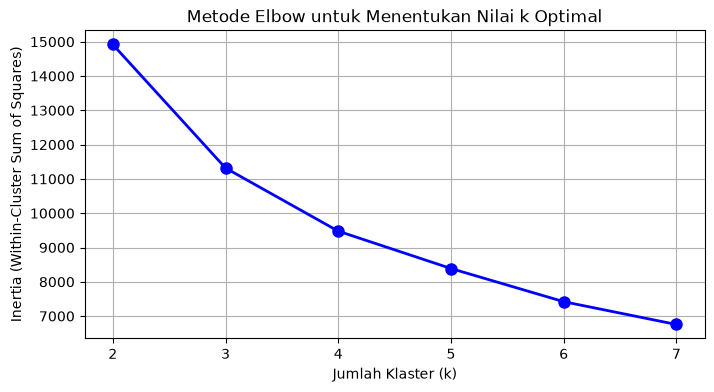

In [2]:
inertia = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_sample)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, 'bo-', linewidth=2, markersize=8)
plt.title('Metode Elbow untuk Menentukan Nilai k Optimal', fontsize=12)
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.grid(True)
plt.show()

### Langkah 3: Melatih Model K-Means (k=3)

Silhouette Score K-Means (k=3): 0.3021


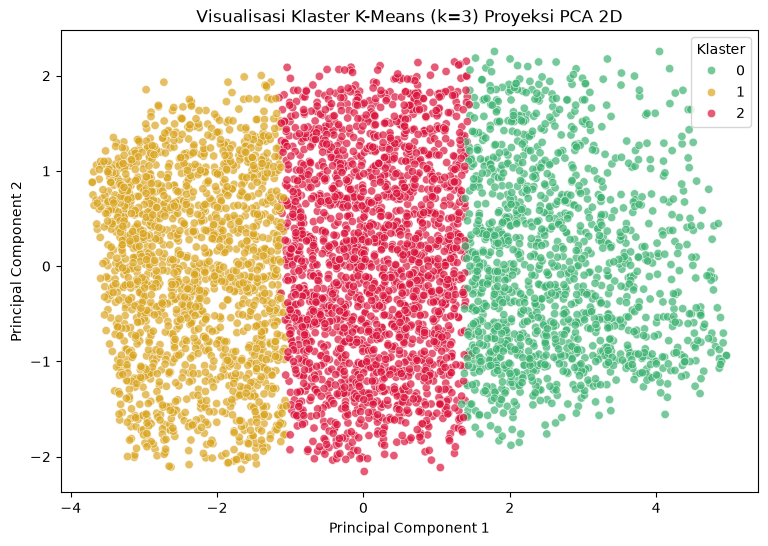

In [3]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_sample)

# Evaluasi Silhouette Score
sil_score = silhouette_score(X_sample, cluster_labels)
print(f"Silhouette Score K-Means (k=3): {sil_score:.4f}")

# Reduksi dimensi ke 2D menggunakan PCA untuk visualisasi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_sample)

plt.figure(figsize=(9, 6))
palette = {0: 'mediumseagreen', 1: 'goldenrod', 2: 'crimson'}
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels, palette=palette, alpha=0.7)
plt.title('Visualisasi Klaster K-Means (k=3) Proyeksi PCA 2D', fontsize=12)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Klaster')
plt.show()

### Langkah 4: Clustering Berbasis Kepadatan (DBSCAN)

In [4]:
dbscan = DBSCAN(eps=1.2, min_samples=10)
db_labels = dbscan.fit_predict(X_sample)

n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = list(db_labels).count(-1)

print(f"DBSCAN Menghasilkan {n_clusters_db} klaster utama dan {n_noise} titik noise/outlier.")

DBSCAN Menghasilkan 1 klaster utama dan 7 titik noise/outlier.


### Kesimpulan JS04:
1. K-Means dengan $k=3$ secara alami memisahkan responden ke dalam 3 segmen: Klaster Sehat (*Low Stress/Healthy*), Klaster Menengah (*Moderate Attention*), dan Klaster Burnout Parah (*Critical/Burnout*).
2. DBSCAN mampu mendeteksi profil pekerja dengan nilai-nilai ekstrem sebagai *noise/outlier*, yang sangat berguna untuk deteksi dini kasus krisis kesehatan mental.